# Analysis of the output

In [1273]:
import pandas as pd

#df = pd.read_excel('./programmer_conversation_llama32_llama32_complete.xlsx', sheet_name='Sheet1')
#df = pd.read_excel('./programmer_conversation_llama32_deepseek3.xlsx', sheet_name='Sheet1')
#df = pd.read_excel('./programmer_conversation_gemma3_minicp.xlsx', sheet_name='Sheet1')
df = pd.read_excel('./programmer_conversation_gemma3_gemma2.xlsx', sheet_name='Sheet1')
df = df[~df['content'].str.contains(r'^\*+$')]

In [1274]:
# select only the rows with role "assistant" and make them into a list
assistant_rows = df[df['role'] == 'assistant']
assistant_rows = assistant_rows[['content']].reset_index(drop=True)
assistant_rows = assistant_rows['content'].tolist()

In [1275]:
len(assistant_rows)

1189

In [1276]:
# for each of the row, calculate BLUE score to the previous one
def calculate_bleu_score(reference, candidate):
    from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
    reference_tokens = reference.split()
    candidate_tokens = candidate.split()
    smoothing = SmoothingFunction().method1
    return sentence_bleu([reference_tokens], candidate_tokens, smoothing_function=smoothing)
bleu_scores = []

for i in range(1, len(assistant_rows)):
    reference = assistant_rows[i-1]
    candidate = assistant_rows[i]
    bleu_score = calculate_bleu_score(reference, candidate)
    bleu_scores.append(bleu_score)

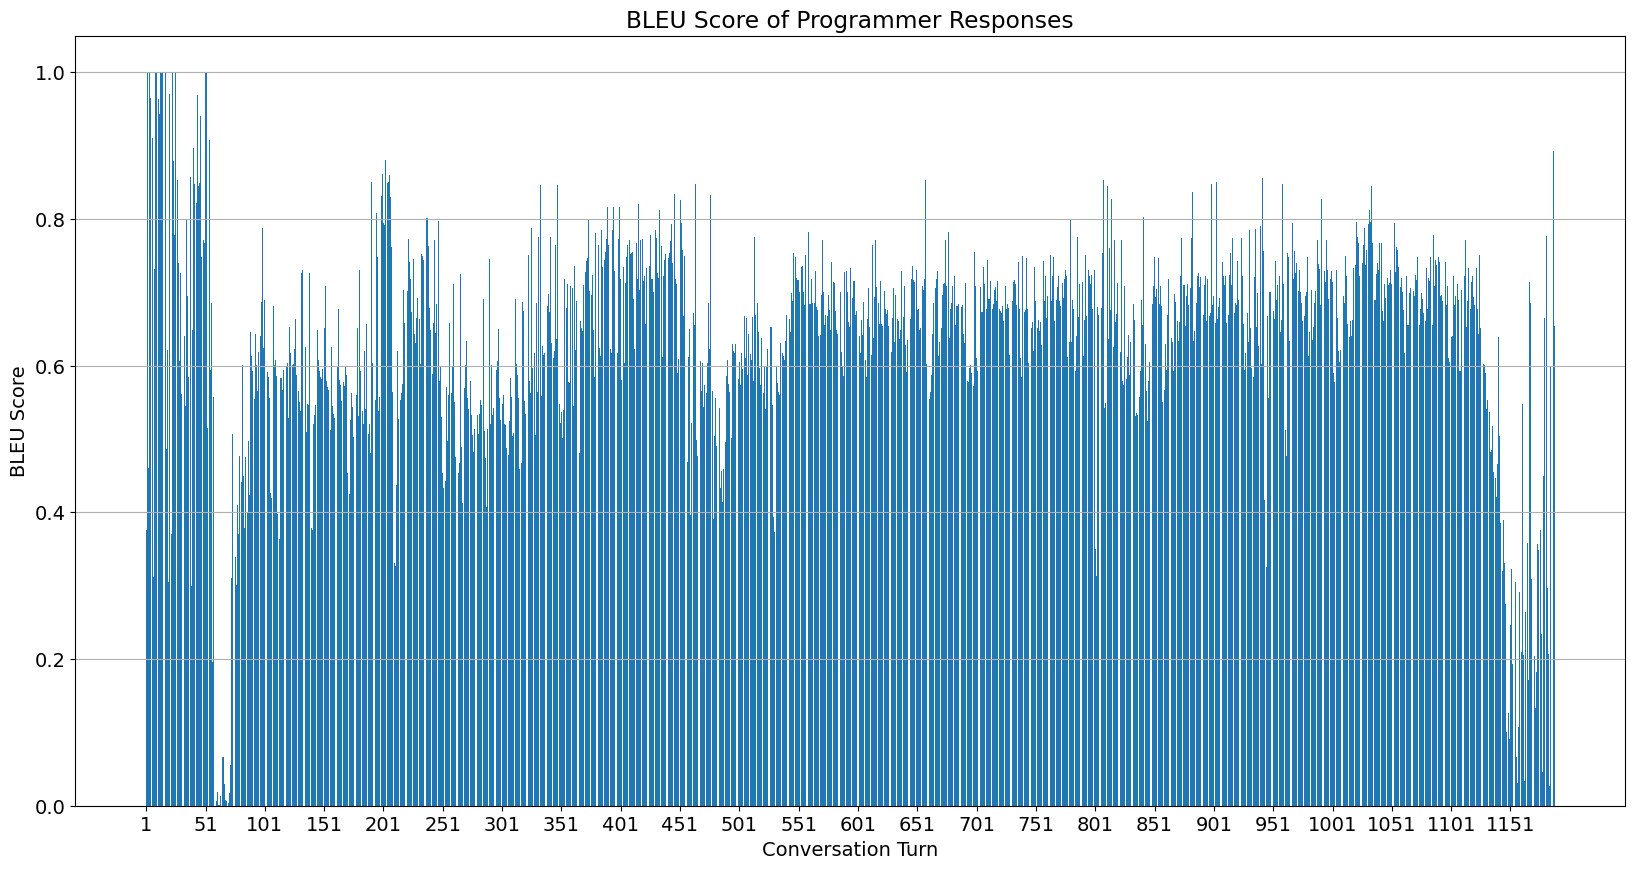

In [1277]:
import matplotlib.pyplot as plt
plt.rcParams.update({'font.size': 14})

plt.figure(figsize=(20, 10))
plt.bar(range(len(bleu_scores)), bleu_scores)
plt.xlabel('Conversation Turn')
plt.ylabel('BLEU Score')
plt.title('BLEU Score of Programmer Responses')
tick_positions = list(range(0, len(bleu_scores), 50))
tick_labels = [str(i+1) for i in tick_positions]
plt.xticks(tick_positions, tick_labels)
plt.grid(axis='y')
plt.show()

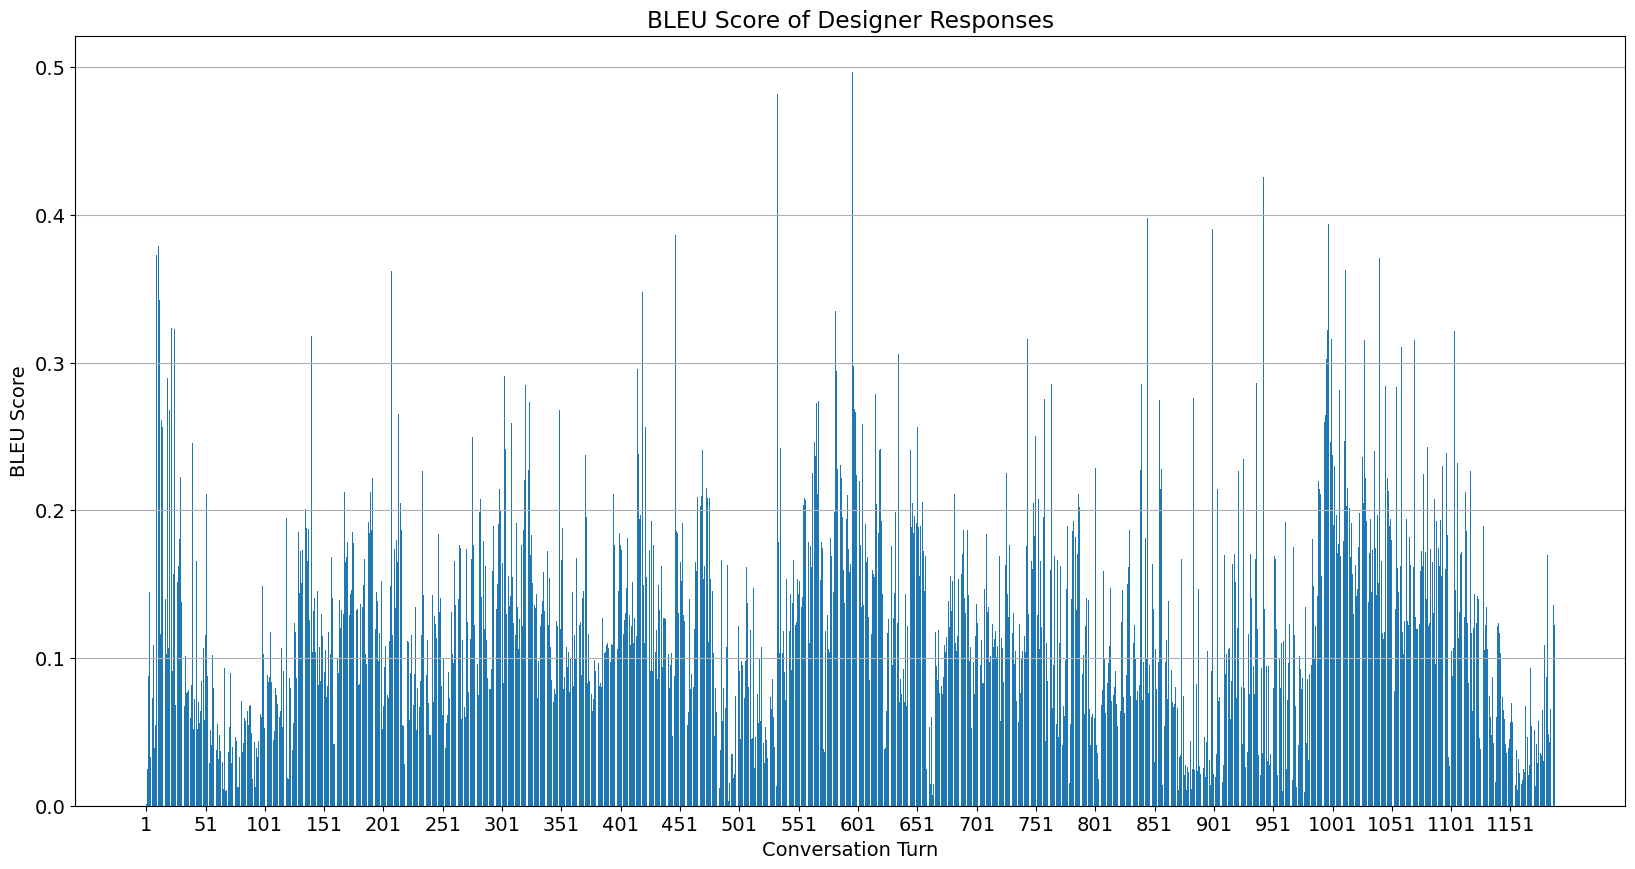

In [1278]:
# now do the same for rows with role "user"
# remove rows that contain only "*" in the content column
user_rows = df[df['role'] == 'user']
user_rows = user_rows[['content']].reset_index(drop=True)
user_rows = user_rows['content'].tolist()

len(user_rows)

# for each of the row, calculate BLUE score to the previous one
bleu_scores = []
for i in range(1, len(user_rows)):
    reference = user_rows[i-1]
    candidate = user_rows[i]
    bleu_score = calculate_bleu_score(reference, candidate)
    bleu_scores.append(bleu_score)

plt.rcParams.update({'font.size': 14})

plt.figure(figsize=(20, 10))
plt.bar(range(len(bleu_scores)), bleu_scores)
plt.xlabel('Conversation Turn')
plt.ylabel('BLEU Score')
plt.title('BLEU Score of Designer Responses')
tick_positions = list(range(0, len(bleu_scores), 50))
tick_labels = [str(i+1) for i in tick_positions]
plt.xticks(tick_positions, tick_labels)
plt.grid(axis='y')
plt.show()

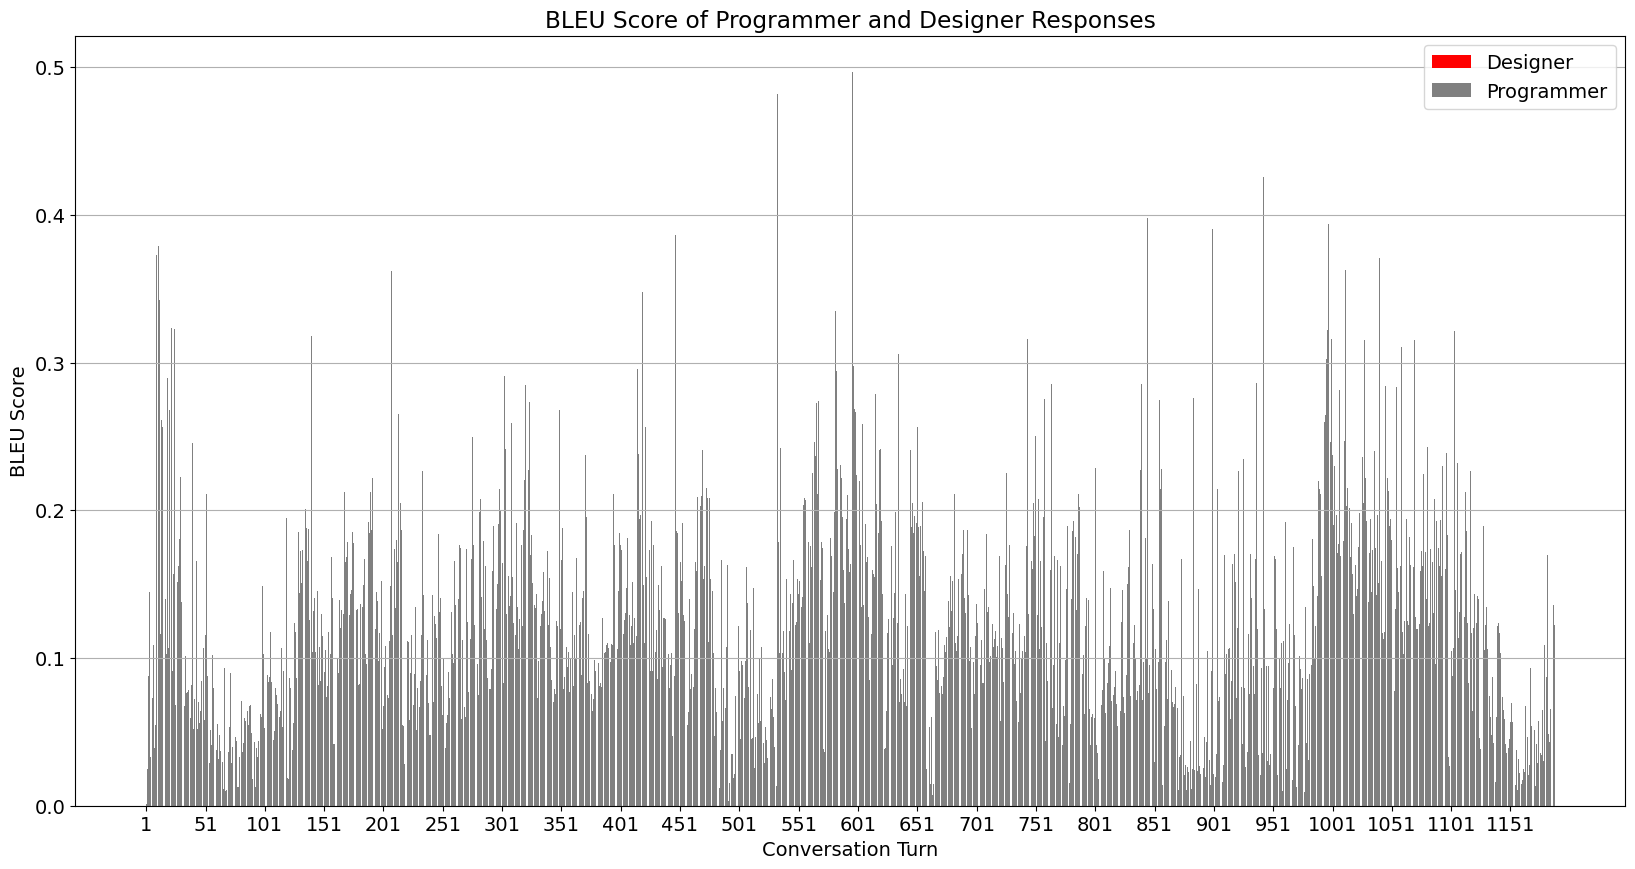

In [1279]:
# now merge these two diagrams, with the programmer in blue and the designer in red
plt.rcParams.update({'font.size': 14})
plt.figure(figsize=(20, 10))
plt.bar(range(len(bleu_scores)), bleu_scores, color='red', label='Designer')
plt.bar(range(len(bleu_scores)), bleu_scores, color='grey', label='Programmer')
plt.xlabel('Conversation Turn')
plt.ylabel('BLEU Score')
plt.title('BLEU Score of Programmer and Designer Responses')
tick_positions = list(range(0, len(bleu_scores), 50))
tick_labels = [str(i+1) for i in tick_positions]
plt.xticks(tick_positions, tick_labels)
plt.grid(axis='y')
plt.legend()

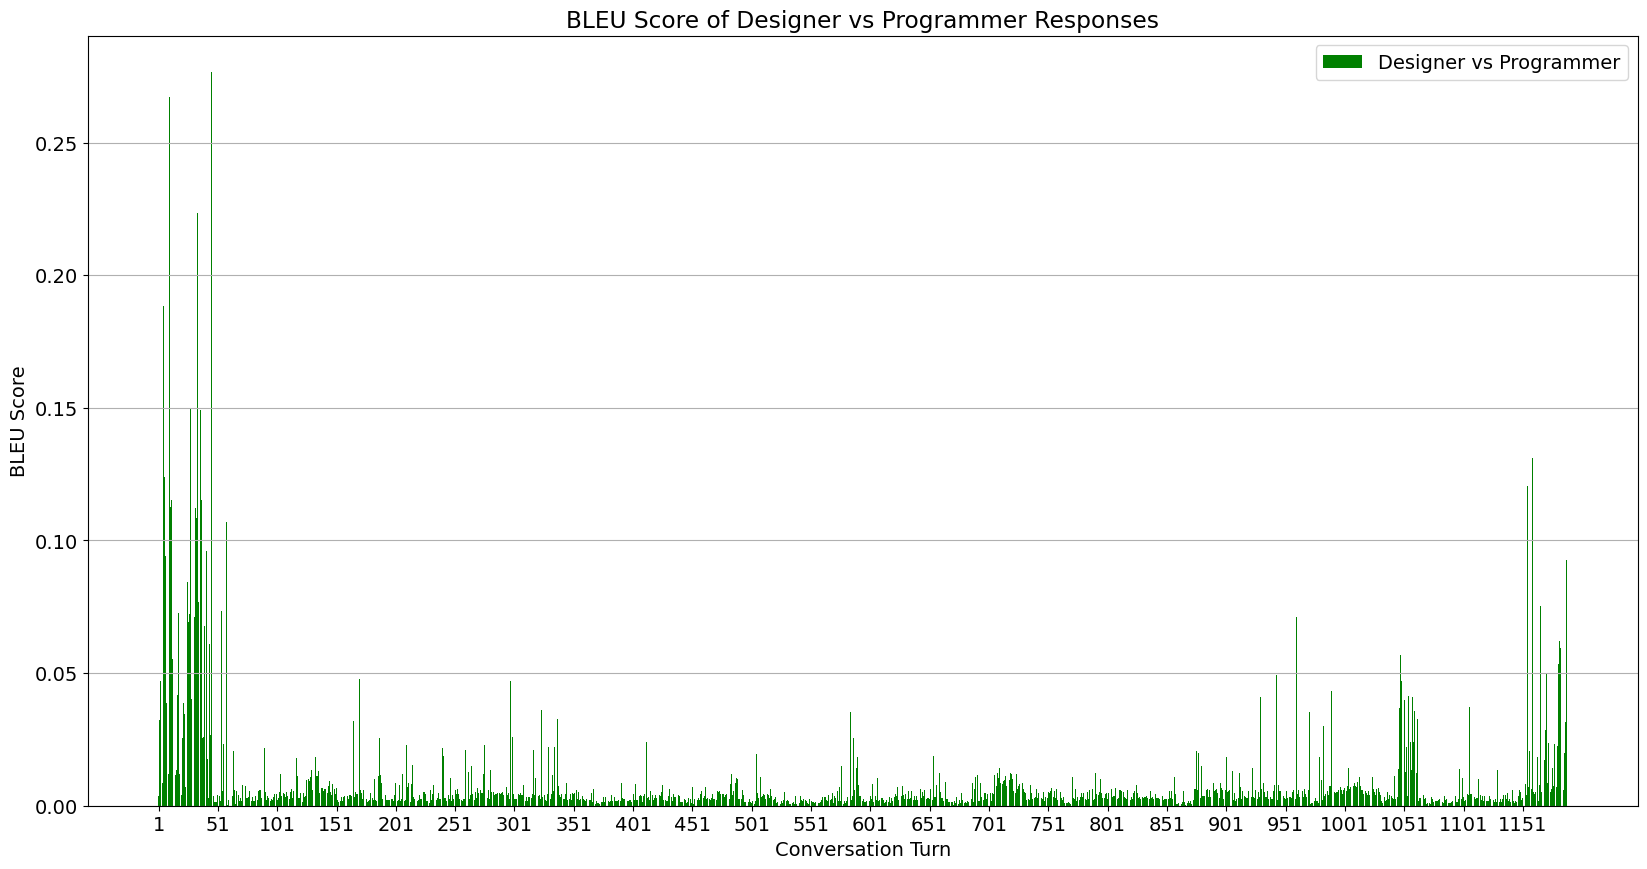

In [1280]:
# now I want to calculate the BLUE score between the two roles
bleu_scores = []
for i in range(1, len(user_rows)):
    reference = user_rows[i-1]
    candidate = assistant_rows[i]
    bleu_score = calculate_bleu_score(reference, candidate)
    bleu_scores.append(bleu_score)
plt.rcParams.update({'font.size': 14})
plt.figure(figsize=(20, 10))
plt.bar(range(len(bleu_scores)), bleu_scores, color='green', label='Designer vs Programmer')
plt.xlabel('Conversation Turn')
plt.ylabel('BLEU Score')
plt.title('BLEU Score of Designer vs Programmer Responses')
tick_positions = list(range(0, len(bleu_scores), 50))
tick_labels = [str(i+1) for i in tick_positions]
plt.xticks(tick_positions, tick_labels)
plt.grid(axis='y')
plt.legend()
plt.show()

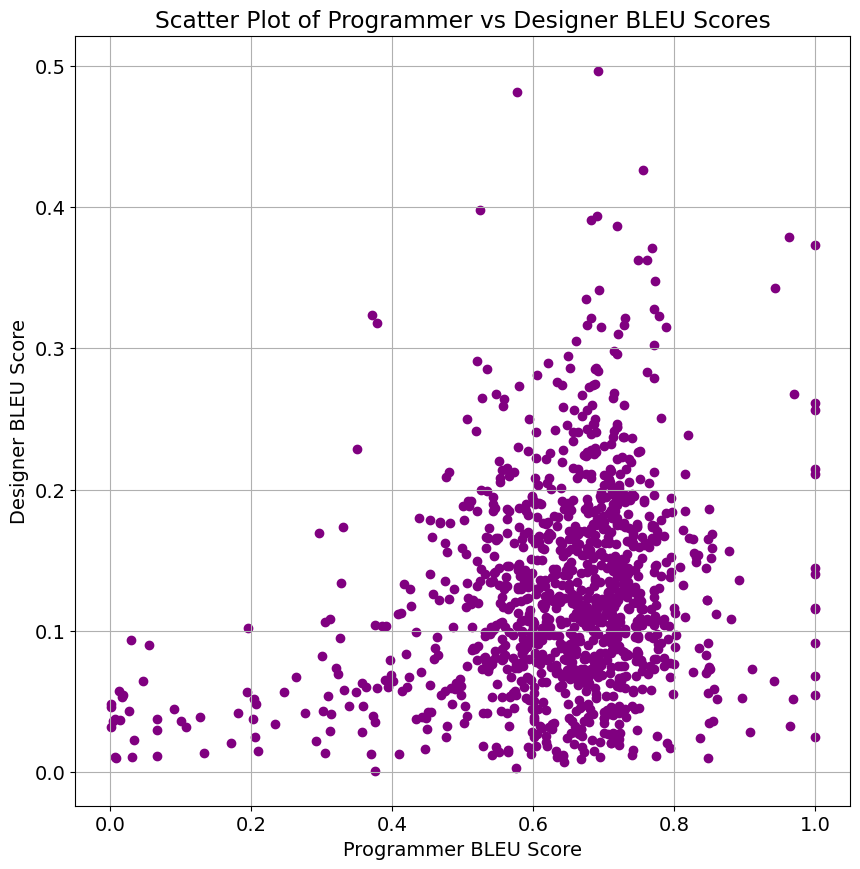

In [1281]:
# Calculate BLEU scores for programmer (assistant) responses
programmer_bleu = []
for i in range(1, len(assistant_rows)):
    reference = assistant_rows[i-1]
    candidate = assistant_rows[i]
    score = calculate_bleu_score(reference, candidate)
    programmer_bleu.append(score)

# Calculate BLEU scores for designer (user) responses
designer_bleu = []
for i in range(1, len(user_rows)):
    reference = user_rows[i-1]
    candidate = user_rows[i]
    score = calculate_bleu_score(reference, candidate)
    designer_bleu.append(score)

# Trim to the minimum length to ensure alignment
min_len = min(len(programmer_bleu), len(designer_bleu))
programmer_bleu = programmer_bleu[:min_len]
designer_bleu = designer_bleu[:min_len]

# Create scatter plot: Programmer on x-axis, Designer on y-axis
import matplotlib.pyplot as plt
plt.rcParams.update({'font.size': 14})
plt.figure(figsize=(10, 10))
plt.scatter(programmer_bleu, designer_bleu, color='purple')
plt.xlabel('Programmer BLEU Score')
plt.ylabel('Designer BLEU Score')
plt.title('Scatter Plot of Programmer vs Designer BLEU Scores')
plt.grid(True)
plt.show()

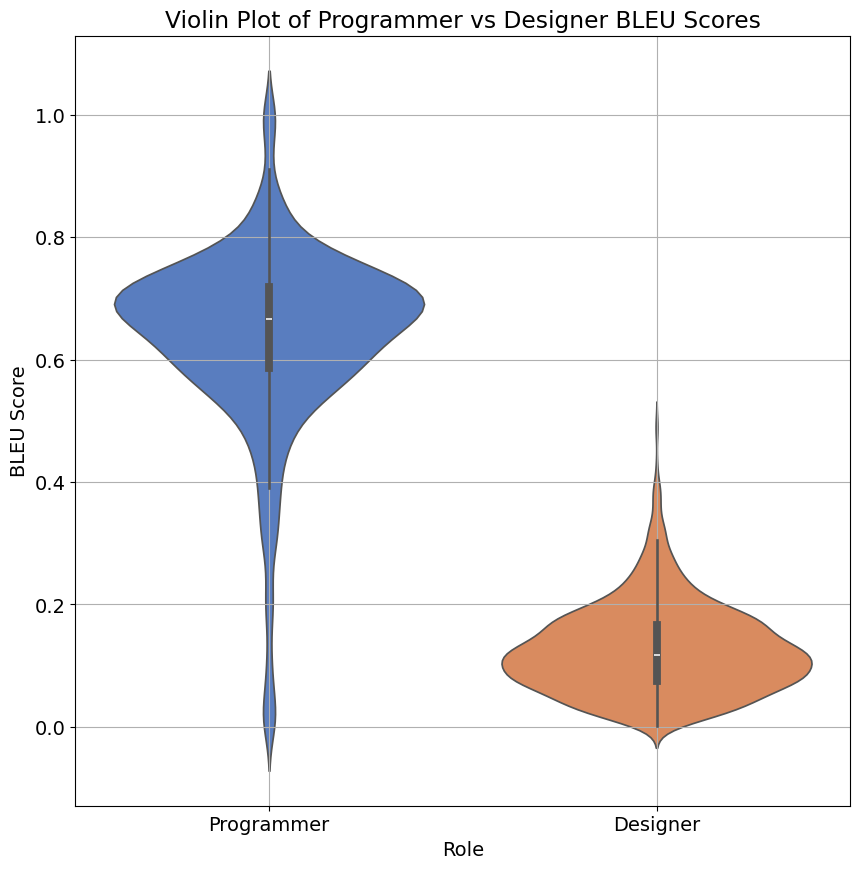

In [1282]:
# now I want a violin plot of the two distributions
import seaborn as sns
plt.rcParams.update({'font.size': 14})
plt.figure(figsize=(10, 10))
sns.violinplot(data=[programmer_bleu, designer_bleu], palette='muted')
plt.xticks([0, 1], ['Programmer', 'Designer'])
plt.xlabel('Role')
plt.ylabel('BLEU Score')
plt.title('Violin Plot of Programmer vs Designer BLEU Scores')
plt.grid(True)
plt.show()

In [1283]:
# now I want to calculate the number of words in each response
def count_words(text):
    return len(text.split())
programmer_word_counts = [count_words(response) for response in assistant_rows]
designer_word_counts = [count_words(response) for response in user_rows]

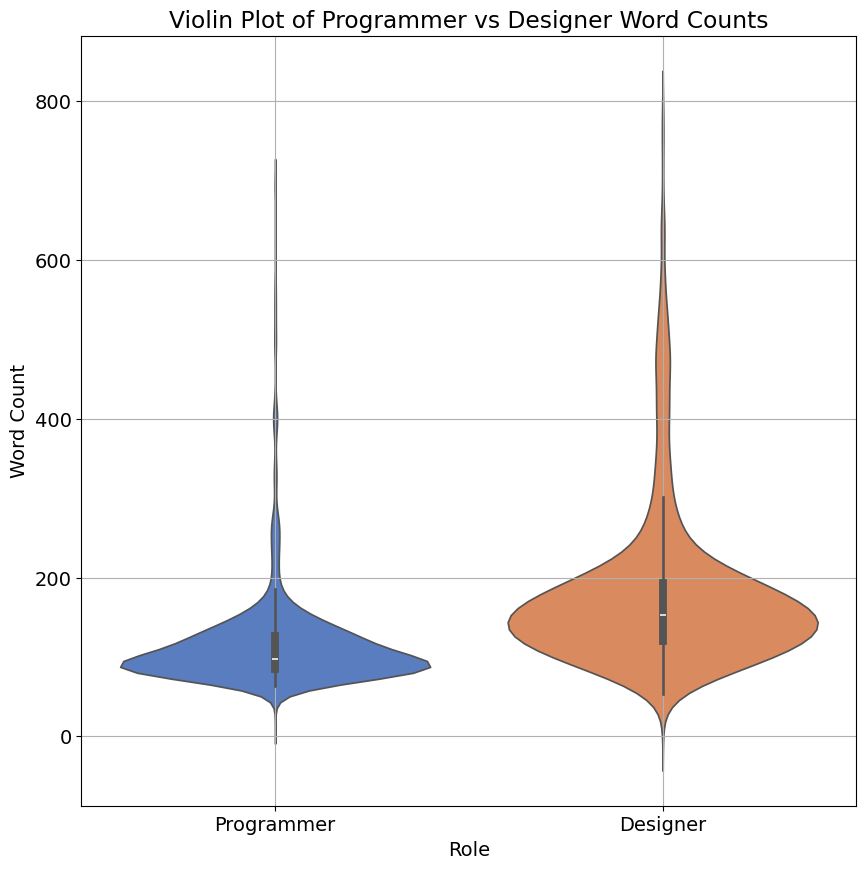

In [1284]:
# now plot this as violin plots
plt.rcParams.update({'font.size': 14})
plt.figure(figsize=(10, 10))
sns.violinplot(data=[programmer_word_counts, designer_word_counts], palette='muted')
plt.xticks([0, 1], ['Programmer', 'Designer'])
plt.xlabel('Role')
plt.ylabel('Word Count')
plt.title('Violin Plot of Programmer vs Designer Word Counts')
plt.grid(True)
plt.show()

In [1285]:
len(programmer_word_counts)

1189

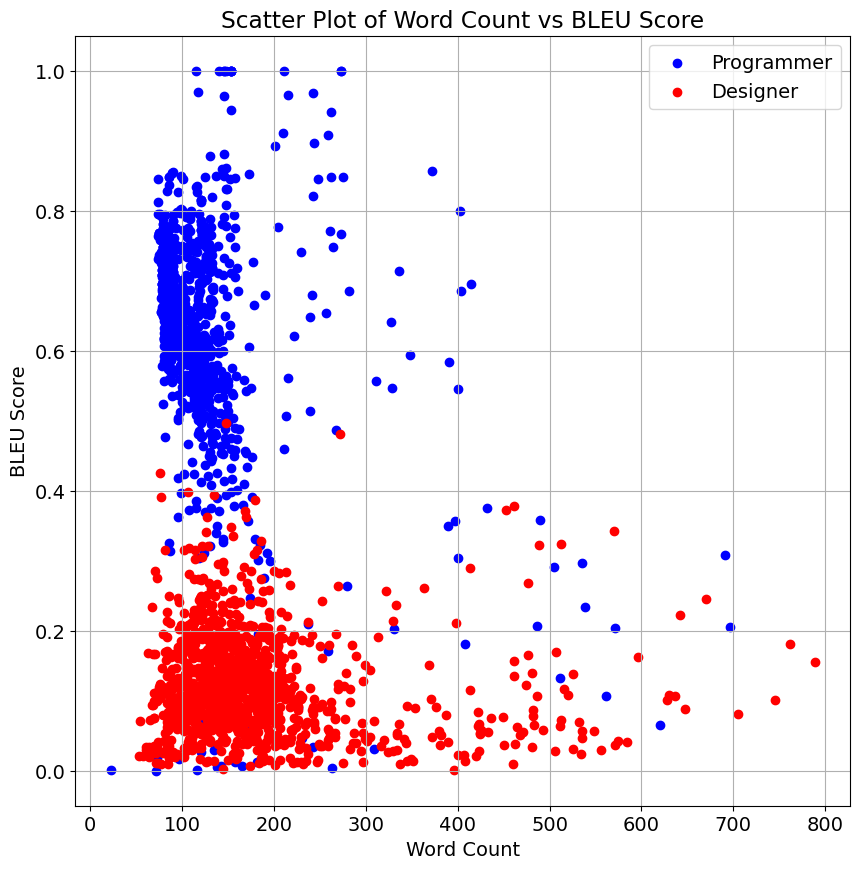

In [1286]:
# now I want the scatter plot between the number of words and the BLUE score
plt.rcParams.update({'font.size': 14})
plt.figure(figsize=(10, 10))
plt.scatter(programmer_word_counts[1:], programmer_bleu, color='blue', label='Programmer')
plt.scatter(designer_word_counts[1:], designer_bleu, color='red', label='Designer')
plt.xlabel('Word Count')
plt.ylabel('BLEU Score')
plt.title('Scatter Plot of Word Count vs BLEU Score')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# now do all that for ROUGE score
def calculate_rouge_score(reference, candidate):
    from rouge import Rouge
    rouge = Rouge()
    scores = rouge.get_scores(candidate, reference)
    return scores[0]['rouge-l']['f']

# Calculate ROUGE scores for programmer (assistant) responses
programmer_rouge = []
for i in range(1, len(assistant_rows)):
    reference = assistant_rows[i-1]
    candidate = assistant_rows[i]
    score = calculate_rouge_score(reference, candidate)
    programmer_rouge.append(score)

# Calculate ROUGE scores for designer (user) responses
designer_rouge = []
for i in range(1, len(user_rows)):
    reference = user_rows[i-1]
    candidate = user_rows[i]
    score = calculate_rouge_score(reference, candidate)
    designer_rouge.append(score)

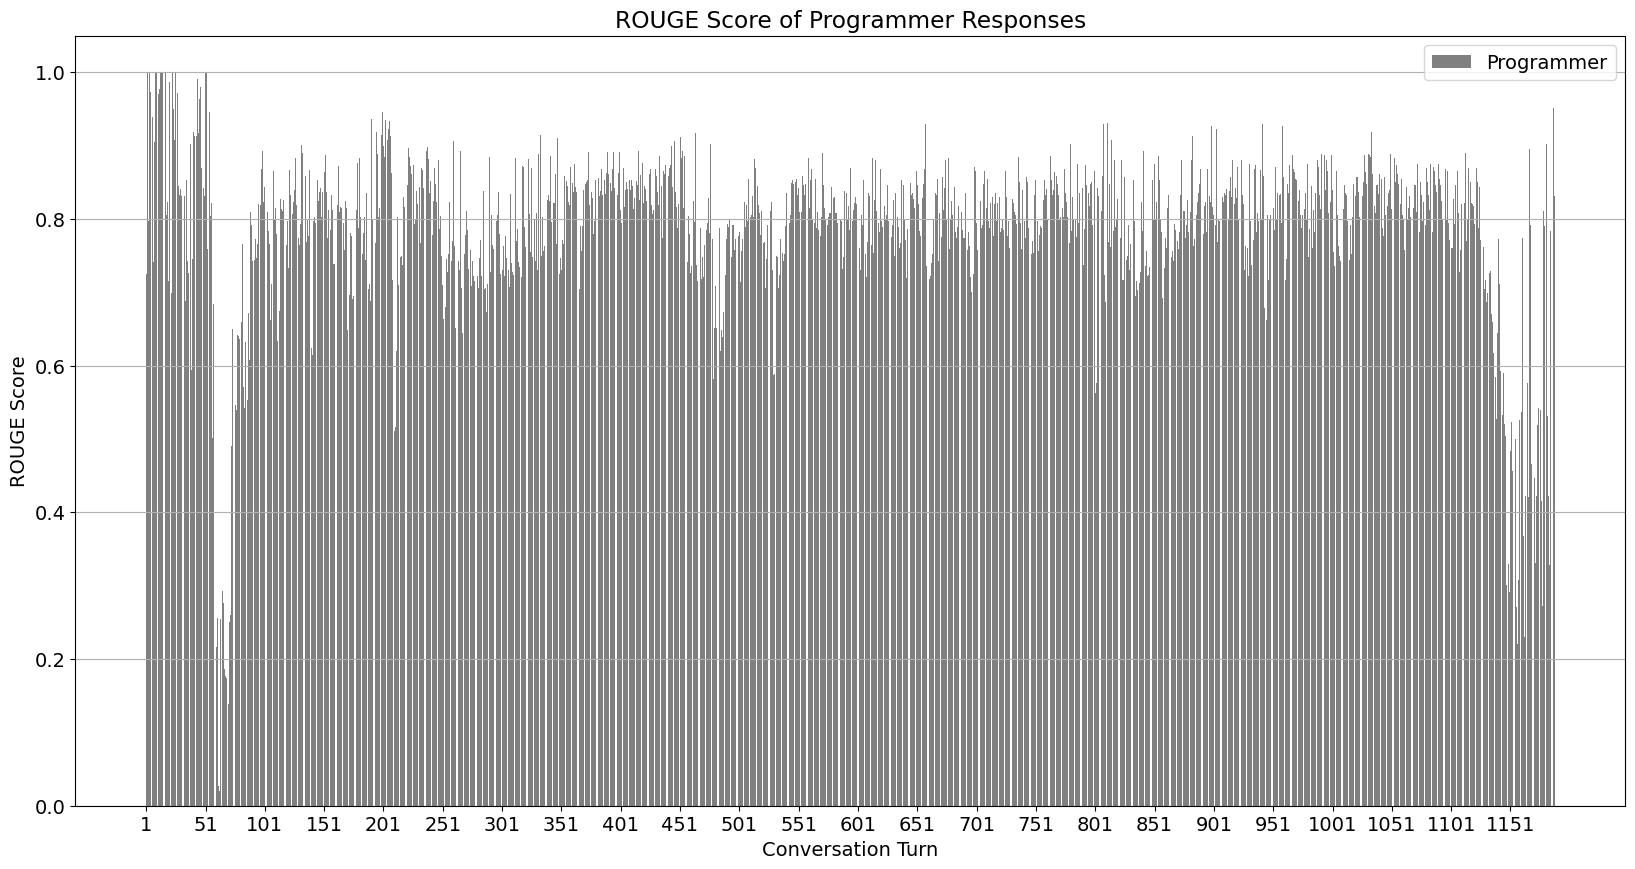

In [ ]:

plt.rcParams.update({'font.size': 14})
plt.figure(figsize=(20, 10))
plt.bar(range(len(programmer_rouge)), programmer_rouge, color='grey', label='Programmer')
plt.xlabel('Conversation Turn')
plt.ylabel('ROUGE Score')
plt.title('ROUGE Score of Programmer Responses')
tick_positions = list(range(0, len(designer_rouge), 50))
tick_labels = [str(i+1) for i in tick_positions]
plt.xticks(tick_positions, tick_labels)
plt.grid(axis='y')
plt.legend()
plt.show()

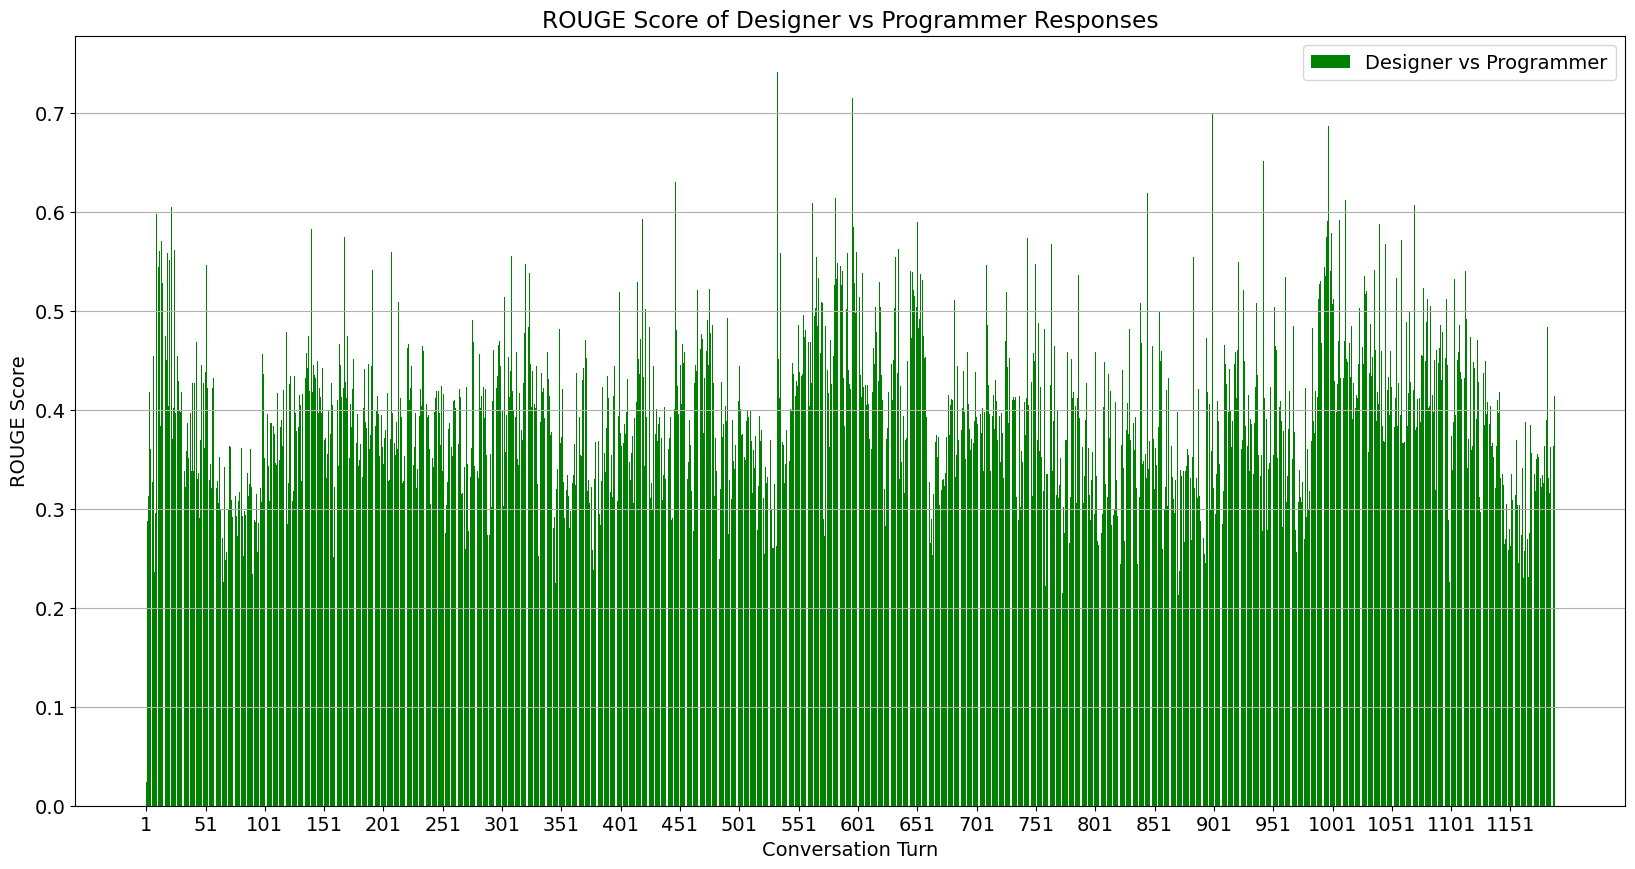

In [1295]:
plt.rcParams.update({'font.size': 14})
plt.figure(figsize=(20, 10))
plt.bar(range(len(designer_rouge)), designer_rouge, color='green', label='Designer vs Programmer')
plt.xlabel('Conversation Turn')
plt.ylabel('ROUGE Score')
plt.title('ROUGE Score of Designer vs Programmer Responses')
tick_positions = list(range(0, len(designer_rouge), 50))
tick_labels = [str(i+1) for i in tick_positions]
plt.xticks(tick_positions, tick_labels)
plt.grid(axis='y')
plt.legend()
plt.show()

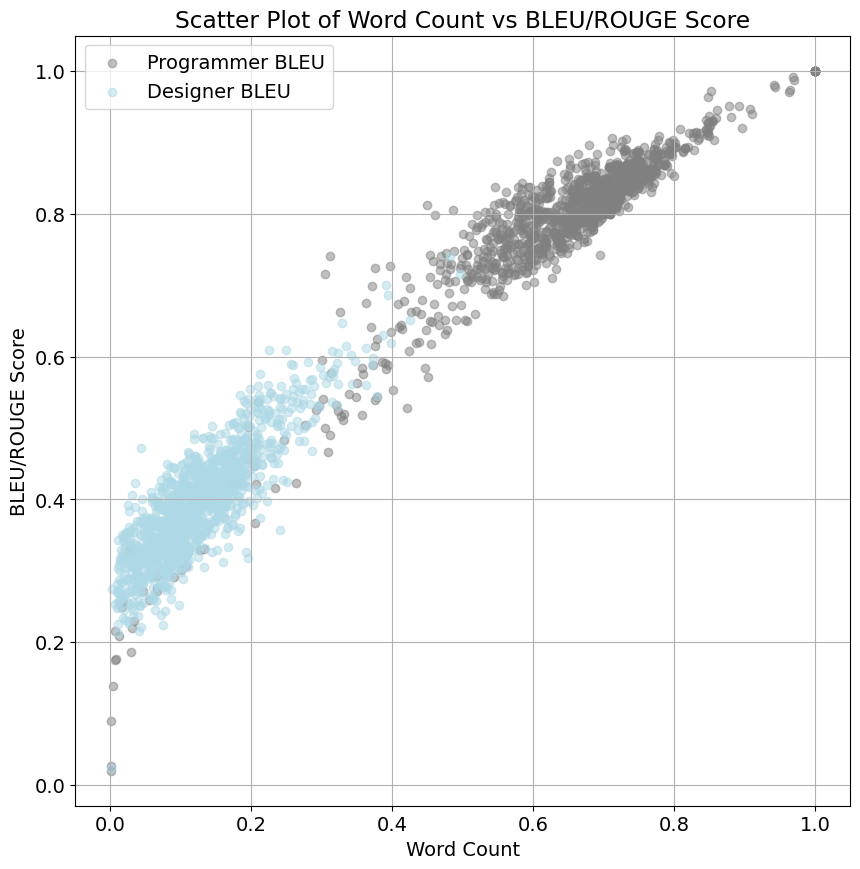

In [1296]:
# visualize scatter plot for BLUE and ROUGE scores
plt.rcParams.update({'font.size': 14})
plt.figure(figsize=(10, 10))
plt.scatter(programmer_bleu, programmer_rouge, color='grey', alpha=0.5, label='Programmer BLEU')
plt.scatter(designer_bleu, designer_rouge, color='lightblue', alpha=0.5, label='Designer BLEU')
plt.xlabel('Word Count')
plt.ylabel('BLEU/ROUGE Score')
plt.title('Scatter Plot of Word Count vs BLEU/ROUGE Score')
plt.legend()
plt.grid(True)
plt.show()